# 04 · Expression — EMT-transcription-factor axis along the trajectory

*(Renumbered from 06: with Gate 2 = GO / Gate 3 = NA the manifold is non-branching, so the
branching-only correlation (04) and modules (05) notebooks are **not** produced — this
unconditional expression notebook follows signatures directly, per §6.)*

Puram 2017 overlays **SNAI1** (root) and **ZEB1** (terminus). Per the **derive-don't-inherit**
mandate we do not inherit that pair: we score a candidate EMT-TF panel — the canonical
Snail/Zeb/Twist factors **plus the mesenchymal / neural-crest FOXC and PRRX factors** (Kürten
lesson) — along *this* trajectory (differentiating-keratinocyte root → neural-crest / TSK
leading-edge terminus), gate out factors below a 3% detection floor, and let the data choose the
most end-specific factor at each end. We then test whether the axis is genuinely **bipolar**
(a root-specific factor opposite a terminus-specific one) or **monotone**, and draw whichever the
data support rather than fabricating a split. VIM is excluded — vimentin is a mesenchymal marker,
not a transcription factor (Chen lesson). Deliverable: `expression.pdf`.

In [ ]:

import os, sys, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, pearsonr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)


### Load the rooted, signature-scored manifold

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 10504 | pseudotime range 0.0 -> 10.79


### Derive the end-specific EMT-TFs (data-driven)
For each candidate TF: fraction expressing, mean expression in early (root) vs late (terminus)
pseudotime tercile, and Spearman correlation with pseudotime. Among factors above a 3% floor,
the most negatively-correlated marks the root end and the most positively-correlated the terminus.

In [ ]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; rho,p = spearmanr(tn, x)
    rows.append((g, round((x>0).mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
early_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']
late_tf  = ok.sort_values('rho_vs_t').iloc[-1]['TF']
print(f'\nderived pair: {early_tf} (early/root) <-> {late_tf} (late/terminus)')
print('3% detection floor applied so near-dropout factors are not overlaid blind (Kürten lesson).')

    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
 PRRX2      0.097       0.041      0.045    -0.016 LATE(terminus)
 SNAI1      0.028       0.012      0.010    -0.014    EARLY(root)
 FOXC1      0.047       0.019      0.023    -0.007 LATE(terminus)
  ZEB2      0.026       0.009      0.013     0.010 LATE(terminus)
  ZEB1      0.008       0.002      0.004     0.012 LATE(terminus)
 PRRX1      0.004       0.001      0.002     0.016 LATE(terminus)
TWIST2      0.001       0.000      0.000     0.020 LATE(terminus)
 FOXC2      0.000       0.000      0.001     0.023 LATE(terminus)
TWIST1      0.002       0.001      0.001     0.030 LATE(terminus)
 SNAI2      0.552       0.225      0.575     0.311 LATE(terminus)

derived pair: PRRX2 (early/root) <-> SNAI2 (late/terminus)
3% detection floor applied so near-dropout factors are not overlaid blind (Kürten lesson).


### Bipolar or monotone axis? (data-driven figure choice)
A bipolar overlay is drawn **only if** the derived early factor is (i) above the 3% floor and
(ii) genuinely root-shifted (its upper-quartile expressers sit early, early↔late separation ≥0.15).
Otherwise the axis is monotone and the honest figure is a graded overlay of the single strongest
end-specific factor, not a fabricated two-colour split.

In [ ]:
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
ve = _vec(early_tf); pe = ve[ve>0]
sel_e = ve > (np.quantile(pe,0.75) if pe.size else np.inf)
early_pt = tn[sel_e].mean() if sel_e.any() else np.nan
vl = _vec(late_tf); pl_ = vl[vl>0]
sel_l = vl > (np.quantile(pl_,0.75) if pl_.size else np.inf)
sep = abs(tn[sel_l].mean() - early_pt)
bipolar = (df.set_index('TF').loc[early_tf,'frac_expr'] > 0.03) and (early_pt < 0.5) and (sep >= 0.15)
print(f'{early_tf} upper-quartile expressers mean pseudotime = {early_pt:.2f}; '
      f'early<->late separation = {sep:.2f} -> axis is {"BIPOLAR" if bipolar else "MONOTONE"}')

PRRX2 upper-quartile expressers mean pseudotime = 0.60; early<->late separation = 0.18 -> axis is MONOTONE


### EMT-TF expression overlay (deliverable)
House style: `figsize=(3.5,1.5)`, pseudotime left→right, `size=30`. If bipolar, the abundant late
marker is drawn first so the sparser early marker reads on top, each thresholded at the upper
quartile among its expressers. If monotone, a single graded colormap of the strongest terminus
factor is shown.

SNAI2: 55.2% expressing, upper-quartile expressers mean pseudotime 0.79 (all=0.53)
EMT axis is monotone | saved expression.pdf


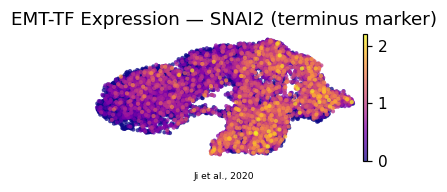

In [ ]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
if bipolar:
    thr = {g: float(np.quantile(_vec(g)[_vec(g)>0],0.75)) for g in [early_tf, late_tf]}
    sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
    order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
    colors = {early_tf:'tab:blue', late_tf:'tab:red'}
    sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
    for g in order:
        sc.pl.umap(adata[sel[g]].copy(), na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
    ax.set_title(f'EMT-TF Expression   {early_tf} (early) · {late_tf} (late)', size=7.5)
    print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in [early_tf,late_tf]},
          '| cells shown:', {g: int(sel[g].sum()) for g in [early_tf,late_tf]})
else:
    sc.pl.umap(adata, color=late_tf, cmap='plasma', size=30, alpha=.75, colorbar_loc='right',
               frameon=False, show=False, ax=ax, title=f'EMT-TF Expression — {late_tf} (terminus marker)')
    print(f'{late_tf}: {(_vec(late_tf)>0).mean()*100:.1f}% expressing, upper-quartile expressers mean pseudotime {tn[sel_l].mean():.2f} (all={tn.mean():.2f})')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.14,'Ji et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
print('EMT axis is', 'bipolar' if bipolar else 'monotone', '| saved expression.pdf')